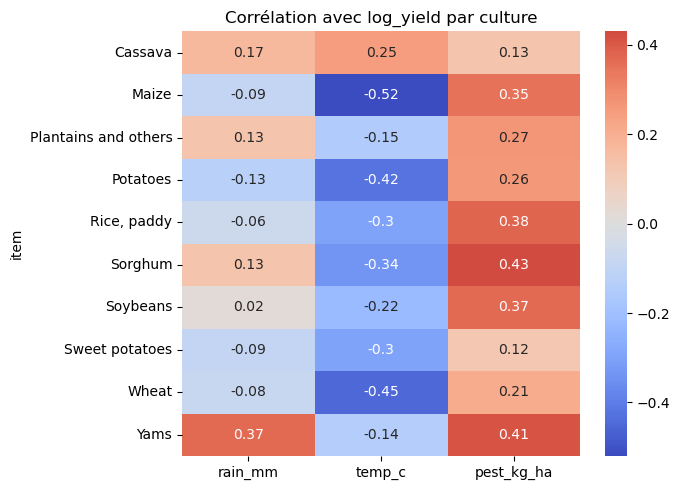

R² test (optimiste, split aléatoire): 0.969
item          1.740128
pest_kg_ha    0.229204
temp_c        0.160400
rain_mm       0.130601
area          0.120234
year          0.037920
dtype: float64


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

SEED = 42

# ---------- 1. Chargement + dédoublonnage de la fusion ----------
df = pd.read_csv("../data/consolidated_yield.csv")

# ---------- 4. Corrélations par culture ----------
num = ["log_yield", "rain_mm", "temp_c", "pest_kg_ha"]
corr_item = (df.groupby("item")[num].corr()["log_yield"]
               .unstack().drop(columns="log_yield").round(2))
plt.figure(figsize=(7, 5))
sns.heatmap(corr_item, annot=True, cmap="coolwarm", center=0)
plt.title("Corrélation avec log_yield par culture")
plt.tight_layout(); plt.show()

# ---------- 5. Importance des variables (RF) ----------
X = pd.get_dummies(df[["area", "item", "year", "rain_mm", "temp_c", "pest_kg_ha"]],
                   columns=["area", "item"])
y = df["log_yield"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=SEED)
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
print("R² test (optimiste, split aléatoire):", round(rf.score(Xte, yte), 3))

perm = permutation_importance(rf, Xte, yte, n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns)
grp = imp.groupby(lambda c: c.split("_")[0] if c.startswith(("area_", "item_")) else c).sum()
print(grp.sort_values(ascending=False))


In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score

groups = df["area"]
feat = ["area", "item", "year", "rain_mm", "temp_c", "pest_kg_ha"]
X = pd.get_dummies(df[feat], columns=["area", "item"])
y = df["log_yield"]

# R² honnête : pays de test jamais vus à l'entraînement
tr, te = next(GroupShuffleSplit(test_size=.2, random_state=SEED).split(X, y, groups))
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED).fit(X.iloc[tr], y.iloc[tr])
print("R² split par pays:", round(r2_score(y.iloc[te], rf.predict(X.iloc[te])), 3))

# Importance par groupe : on permute toutes les colonnes du groupe ensemble
rng = np.random.default_rng(SEED)
Xte, yte = X.iloc[te], y.iloc[te]
base = r2_score(yte, rf.predict(Xte))
blocks = {"item": [c for c in X if c.startswith("item_")],
          "area": [c for c in X if c.startswith("area_")],
          "year": ["year"], "rain_mm": ["rain_mm"],
          "temp_c": ["temp_c"], "pest_kg_ha": ["pest_kg_ha"]}
res = {}
for name, cols in blocks.items():
    drops = []
    for _ in range(5):
        Xp = Xte.copy()
        Xp[cols] = Xp[cols].iloc[rng.permutation(len(Xp))].values  # permute les lignes du bloc entier
        drops.append(base - r2_score(yte, rf.predict(Xp)))
    res[name] = np.mean(drops)
print(pd.Series(res).sort_values(ascending=False).round(3))

R² split par pays: 0.781
item          1.347
pest_kg_ha    0.176
temp_c        0.087
rain_mm       0.060
year          0.013
area          0.000
dtype: float64
